# Section 1: Dataset Understanding

This section introduces the Online Retail dataset, examines its structure and columns, and explores the data to understand the information available before cleaning and analysis.

## Step 1: Import Libraries
Import the required Python libraries for data analysis and visualization. Pandas is used for data manipulation, while Matplotlib and Seaborn are used to create charts and visualizations

In [162]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np





## Step 2: Loading Dataset

Load the Online Retail Excel dataset into a Pandas DataFrame. Display the first three records to confirm that the data has loaded correctly.



In [163]:
df = pd.read_excel("/content/drive/MyDrive/Online Retail.xlsx")

print("First 3 rows of the dataset:")
display(df.head(3))



print("Dataset loaded successfully!")

First 3 rows of the dataset:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom


Dataset loaded successfully!


## Step 3: Dataset Understanding and Initial Exploration
Explore the dataset's structure, size, column names, data types, missing-value information, and statistical summaries to understand the data before beginning the cleaning process.

# Display the first five rows of the dataset to preview the records and understand how the data is organized.

In [164]:
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Display the last five rows of the dataset to inspect the final records and check how the data ends.

In [165]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


# Review the dataset's structure, including column names, data types, non-null values, and memory usage.

In [166]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# Check the number of rows and columns to understand the overall size of the dataset.

In [167]:
df.shape

(541909, 8)

# Examine the data type of each column to identify which fields may need conversion during data preparation.

In [168]:
df.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object


# Generate descriptive statistics for all columns to understand numerical distributions and the values contained in categorical fields.

In [169]:

df.describe(include="all").T


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Display all column names to identify the information available for the analysis.

In [170]:
print("Columns:", df.columns.tolist())


Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


# Section 2: Data Cleaning and Preparation

This section examines data quality issues and prepares the Online Retail dataset for reliable sales analysis. It investigates missing values, duplicate records, cancelled invoices, invalid quantities, and prices. It also prepares the date and revenue columns and creates a separate cleaned sales dataset while preserving the original data.

## Step 1: Preserve the Original Dataset

Create an unchanged copy of the original dataset and a separate working copy for data cleaning. This protects the original records and allows changes to be made safely.

In [171]:
# Keep an unchanged copy of the original dataset
df_raw = df.copy()

# Create a separate working copy for data preparation
df_work = df.copy()

# Verify that both datasets have the same dimensions
print("Original dataset dimensions:", df_raw.shape)
print("Working dataset dimensions:", df_work.shape)

print("\nOriginal dataset preserved.")
print("Working dataset created successfully.")

Original dataset dimensions: (541909, 8)
Working dataset dimensions: (541909, 8)

Original dataset preserved.
Working dataset created successfully.


### Interpretation:

Create an unchanged copy of the original dataset and a separate working copy for data quality assessment and cleaning. This protects the original records and allows us to track changes safely.

## Step 2: Identify Missing Values

Calculate the number and percentage of missing values in each column. This helps identify incomplete information and determine which columns require further investigation.

In [172]:
missing_summary = pd.DataFrame({
    "Missing_Count": df_work.isna().sum(),
    "Missing_Percentage": df_work.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
).round(2)

display(missing_summary)

,Missing_Count,Missing_Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


## Step 3: Identify Duplicate Records

Check the working dataset for exact duplicate rows. Exact duplicates contain identical values across all columns and may cause sales figures to be counted more than once.

In [173]:
# Count exact duplicate rows
duplicate_count = df_work.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 5268


### Removing Duplicate Records

Remove exact duplicate rows from the working dataset and verify that no duplicates remain. The original dataset is preserved separately.

In [174]:
duplicate_count = df_work.duplicated().sum()

print("Duplicate records identified:", duplicate_count)

df_work = df_work.drop_duplicates().copy()

print("Dataset after removing duplicates:", df_work.shape)
print("Remaining duplicate records:", df_work.duplicated().sum())

Duplicate records identified: 5268
Dataset after removing duplicates: (536641, 8)
Remaining duplicate records: 0


## Step 4: Identify Cancelled Invoices

Identify transactions with invoice numbers beginning with the letter C, which indicates cancelled invoices in the Online Retail dataset. Count these records and inspect examples before excluding them from valid sales analysis.

In [175]:
# Identify invoice numbers beginning with C
cancellations = df_work[
    df_work['InvoiceNo'].astype(str).str.startswith('C')
]

# Calculate cancellation records and percentage
cancellation_count = len(cancellations)
cancellation_percentage = (
    cancellation_count / len(df_work)
) * 100

print("Potential cancellation records:", cancellation_count)
print("Percentage of dataset:", round(cancellation_percentage, 2), "%")

# Display 10 examples
display(
    cancellations[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'CustomerID']
    ].head(10)
)

Potential cancellation records: 9251
Percentage of dataset: 1.72 %


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
141,C536379,D,Discount,-1,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0


## Step 5: Identify Negative Quantities

Identify transactions containing negative quantities. These may represent product returns or other non-standard transactions. Count and inspect these records to understand their impact on sales analysis.

In [176]:
# Identify records with negative quantities
negative_quantity = df_work[
    df_work['Quantity'] < 0
]

# Calculate the number and percentage
negative_count = len(negative_quantity)
negative_percentage = (
    negative_count / len(df_work)
) * 100

print("Negative quantity records:", negative_count)
print("Percentage of dataset:", round(negative_percentage, 2), "%")

# Display 10 examples
display(
    negative_quantity[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'CustomerID']
    ].head(10)
)

Negative quantity records: 10587
Percentage of dataset: 1.97 %


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
141,C536379,D,Discount,-1,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0


## Step 6: Identify Zero and Negative Prices

Identify transactions with zero or negative unit prices. Count each category separately and inspect examples to understand which records should be excluded from valid sales calculations.

In [177]:
# Identify records with zero or negative prices
invalid_prices = df_work[
    df_work['UnitPrice'] <= 0
]

# Count zero-price and negative-price records separately
zero_price_count = (df_work['UnitPrice'] == 0).sum()
negative_price_count = (df_work['UnitPrice'] < 0).sum()

print("Zero-price records:", zero_price_count)
print("Negative-price records:", negative_price_count)
print("Total zero or negative price records:", len(invalid_prices))

# Display 10 examples
display(
    invalid_prices[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'CustomerID']
    ].head(10)
)

Zero-price records: 2510
Negative-price records: 2
Total zero or negative price records: 2512


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.0,NaN
1970,536545,21134,NaN,1,0.0,NaN
1971,536546,22145,NaN,1,0.0,NaN
1972,536547,37509,NaN,1,0.0,NaN
1987,536549,85226A,NaN,1,0.0,NaN
1988,536550,85044,NaN,1,0.0,NaN
2024,536552,20950,NaN,1,0.0,NaN
2025,536553,37461,NaN,3,0.0,NaN
2026,536554,84670,NaN,23,0.0,NaN
2406,536589,21777,NaN,-10,0.0,NaN


## Step 7: Investigate Missing Customer IDs

Identify transactions without a CustomerID and calculate their number and percentage. Inspect sample records to understand how missing customer information affects customer-level analysis.

In [178]:
# Identify records with missing CustomerID
missing_customers = df_work[
    df_work['CustomerID'].isna()
]

# Calculate count and percentage
missing_customer_count = len(missing_customers)
missing_customer_percentage = (
    missing_customer_count / len(df_work)
) * 100

print("Records without CustomerID:", missing_customer_count)
print("Percentage of dataset:", round(missing_customer_percentage, 2), "%")

# Display 10 examples
display(
    missing_customers[
        ['InvoiceNo', 'StockCode', 'Description',
         'Quantity', 'UnitPrice', 'InvoiceDate', 'Country']
    ].head(10)
)

Records without CustomerID: 135037
Percentage of dataset: 25.16 %


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate,Country
622,536414,22139,NaN,56,0.00,2010-12-01 11:52:00,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2.51,2010-12-01 14:32:00,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2.51,2010-12-01 14:32:00,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,0.85,2010-12-01 14:32:00,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,1.66,2010-12-01 14:32:00,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,1.66,2010-12-01 14:32:00,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2.51,2010-12-01 14:32:00,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,0.43,2010-12-01 14:32:00,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,0.43,2010-12-01 14:32:00,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,0.43,2010-12-01 14:32:00,United Kingdom


## Step 8: Convert InvoiceDate to Datetime

Check the current data type of InvoiceDate and convert it to datetime format. This allows us to perform time-based analysis, such as monthly revenue and order trends.

In [179]:
# Check the current date data type
print("Before conversion:", df_work['InvoiceDate'].dtype)

# Check missing dates before conversion
print("Missing dates before conversion:", df_work['InvoiceDate'].isna().sum())

# Convert InvoiceDate to datetime
df_work['InvoiceDate'] = pd.to_datetime(
    df_work['InvoiceDate'],
    errors='coerce'
)

# Verify conversion
print("After conversion:", df_work['InvoiceDate'].dtype)
print("Missing or invalid dates after conversion:", df_work['InvoiceDate'].isna().sum())

Before conversion: datetime64[ns]
Missing dates before conversion: 0
After conversion: datetime64[ns]
Missing or invalid dates after conversion: 0


## Step 9: Calculate Revenue

Create a new Revenue column by multiplying Quantity by UnitPrice. This calculates the revenue generated by each transaction line.

In [180]:
df_work['Revenue'] = df_work['Quantity'] * df_work['UnitPrice']

display(
    df_work[['Quantity', 'UnitPrice', 'Revenue']].head(10)
)

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


## Step 10: Check Identifier Data Types

Check the data types of InvoiceNo and StockCode. These columns represent transaction and product identifiers, so they should be treated as identifiers rather than numerical measurements.

In [181]:
print(df_work[['InvoiceNo', 'StockCode']].dtypes)

InvoiceNo    object
StockCode    object
dtype: object


## Step 11: Create the Cleaned Sales Dataset

Create a separate dataset containing valid sales transactions. Exclude cancelled invoices, transactions with negative or zero quantities, and transactions with zero or negative prices. Keep the working dataset unchanged for reference.

In [182]:
df_sales = df_work[
    (~df_work['InvoiceNo'].astype(str).str.startswith('C')) &
    (df_work['Quantity'] > 0) &
    (df_work['UnitPrice'] > 0)
].copy()

print("Original working dataset:", df_work.shape)
print("Cleaned sales dataset:", df_sales.shape)

Original working dataset: (536641, 9)
Cleaned sales dataset: (524878, 9)


In [183]:

# Count records removed at each cleaning step

# Step 1: Cancelled invoices
cancelled = df_work[
    df_work['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove cancelled invoices before checking other conditions
remaining = df_work[
    ~df_work['InvoiceNo'].astype(str).str.startswith('C')
]

# Step 2: Non-positive quantities
invalid_quantity = remaining[remaining['Quantity'] <= 0]

remaining_after_quantity = remaining[
    remaining['Quantity'] > 0
]

# Step 3: Non-positive unit prices
invalid_price = remaining_after_quantity[
    remaining_after_quantity['UnitPrice'] <= 0
]

print("CANCELLED INVOICES:", len(cancelled))
print("NON-POSITIVE QUANTITIES:", len(invalid_quantity))
print("NON-POSITIVE PRICES:", len(invalid_price))

print("\nTotal records excluded:",
      len(cancelled) + len(invalid_quantity) + len(invalid_price))

print("Final cleaned records:", len(df_sales))


CANCELLED INVOICES: 9251
NON-POSITIVE QUANTITIES: 1336
NON-POSITIVE PRICES: 1176

Total records excluded: 11763
Final cleaned records: 524878


In [184]:

# Measure the impact of excluded transactions

# Cancelled invoices
cancelled = df_work[
    df_work['InvoiceNo'].astype(str).str.startswith('C')
].copy()

# Potential returns: negative quantities in non-cancelled invoices
non_cancelled = df_work[
    ~df_work['InvoiceNo'].astype(str).str.startswith('C')
]

returns = non_cancelled[
    non_cancelled['Quantity'] < 0
].copy()

# Zero quantity transactions
zero_quantity = non_cancelled[
    non_cancelled['Quantity'] == 0
]

# Invalid prices after excluding cancelled invoices
# and non-positive quantities
positive_quantity = non_cancelled[
    non_cancelled['Quantity'] > 0
]

invalid_prices = positive_quantity[
    positive_quantity['UnitPrice'] <= 0
].copy()

# Calculate revenue for each excluded group
for data in [cancelled, returns, invalid_prices]:
    data['Excluded_Revenue'] = data['Quantity'] * data['UnitPrice']

print("CANCELLED INVOICES")
print("Records:", len(cancelled))
print("Unique invoices:", cancelled['InvoiceNo'].nunique())
print("Quantity:", cancelled['Quantity'].sum())
print("Revenue:", cancelled['Excluded_Revenue'].sum())

print("\nPOTENTIAL RETURNS")
print("Records:", len(returns))
print("Unique invoices:", returns['InvoiceNo'].nunique())
print("Returned units:", abs(returns['Quantity'].sum()))
print("Return value:", abs(returns['Excluded_Revenue'].sum()))

print("\nZERO QUANTITY TRANSACTIONS")
print("Records:", len(zero_quantity))

print("\nNON-POSITIVE PRICE TRANSACTIONS")
print("Records:", len(invalid_prices))
print("Revenue:", invalid_prices['Excluded_Revenue'].sum())


CANCELLED INVOICES
Records: 9251
Unique invoices: 3836
Quantity: -275560
Revenue: -893979.73

POTENTIAL RETURNS
Records: 1336
Unique invoices: 1336
Returned units: 206957
Return value: 0.0

ZERO QUANTITY TRANSACTIONS
Records: 0

NON-POSITIVE PRICE TRANSACTIONS
Records: 1176
Revenue: -22124.12


In [185]:

# Investigate the potential returns

print("Return data types:")
print(returns[['Quantity', 'UnitPrice']].dtypes)

print("\nFirst 10 potential return records:")
display(returns[['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice']].head(10))

print("\nReturn UnitPrice summary:")
print(returns['UnitPrice'].describe())

print("\nNumber of returns with non-zero prices:")
print((returns['UnitPrice'] != 0).sum())

print("\nTotal return revenue:")
print((returns['Quantity'] * returns['UnitPrice']).sum())


Return data types:
Quantity       int64
UnitPrice    float64
dtype: object

First 10 potential return records:


,InvoiceNo,StockCode,Quantity,UnitPrice
2406,536589,21777,-10,0.0
4347,536764,84952C,-38,0.0
7188,536996,22712,-20,0.0
7189,536997,22028,-20,0.0
7190,536998,85067,-6,0.0
7192,537000,21414,-22,0.0
7193,537001,21653,-6,0.0
7195,537003,85126,-2,0.0
7196,537004,21814,-30,0.0
7197,537005,21692,-70,0.0



Return UnitPrice summary:
count    1336.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: UnitPrice, dtype: float64

Number of returns with non-zero prices:
0

Total return revenue:
0.0


## Step 12: Validate the Cleaned Sales Dataset

Perform final validation checks to confirm that the cleaned dataset has no duplicate records, cancelled invoices, non-positive quantities, or non-positive prices. Also verify missing invoice dates, revenue calculations, and identifier data types.

In [186]:
print("CLEANED SALES DATA VALIDATION")

print("Dataset shape:", df_sales.shape)

print("Remaining duplicates:", df_sales.duplicated().sum())

print(
    "Cancelled invoices:",
    df_sales['InvoiceNo'].astype(str).str.startswith('C').sum()
)

print("Non-positive quantities:", (df_sales['Quantity'] <= 0).sum())

print("Non-positive prices:", (df_sales['UnitPrice'] <= 0).sum())

print("Missing invoice dates:", df_sales['InvoiceDate'].isna().sum())

print("\nRevenue calculation check:")
print(
    (df_sales['Revenue'] == df_sales['Quantity'] * df_sales['UnitPrice']).all()
)

print("\nIdentifier data types:")
print(df_sales[['InvoiceNo', 'StockCode']].dtypes)

CLEANED SALES DATA VALIDATION
Dataset shape: (524878, 9)
Remaining duplicates: 0
Cancelled invoices: 0
Non-positive quantities: 0
Non-positive prices: 0
Missing invoice dates: 0

Revenue calculation check:
True

Identifier data types:
InvoiceNo    object
StockCode    object
dtype: object


## Data Cleaning Decisions and Summary

The following data cleaning and preparation steps were completed:

1. **Missing Values:** Missing CustomerIDs and product descriptions were investigated. Records were retained in the cleaned sales dataset when they otherwise met the valid sales criteria.

2. **Duplicate Records:** Exact duplicate rows were identified and removed from the working dataset. The original dataset was preserved in `df_raw`.

3. **Cancelled Invoices:** Invoices beginning with the letter "C" were identified as cancelled transactions and excluded from the cleaned sales dataset.

4. **Negative Quantities and Returns:** Transactions with negative quantities were investigated as potential returns and excluded from the valid sales performance analysis. This means the analysis focuses on positive sales transactions rather than net sales after returns.

5. **Zero and Negative Prices:** Transactions with non-positive unit prices were investigated and excluded from valid sales analysis.

6. **Invoice Date:** The `InvoiceDate` column was converted to datetime format to support time-based analysis.

7. **Revenue Calculation:** A new `Revenue` column was created using the formula:

   `Revenue = Quantity × UnitPrice`

8. **Identifiers:** `InvoiceNo` and `StockCode` were treated as text identifiers rather than numerical measurements.

9. **Cleaned Dataset:** A separate dataset named `df_sales` was prepared for sales performance and customer and product analysis.

### Final Cleaning Results

The final cleaned sales dataset contains **524,878 transaction records and 9 columns**.

Validation confirmed that the cleaned dataset contains:
- No exact duplicate rows.
- No cancelled invoices.
- No non-positive quantities.
- No non-positive unit prices.
- No missing invoice dates.
- Correctly calculated Revenue values.

### Missing CustomerID Treatment

Missing CustomerID values were retained in valid sales transactions because they may still represent genuine purchases. These transactions were included in overall sales analysis but excluded from customer-level analysis because their customers could not be identified.

Missing product descriptions were also investigated. Valid sales records were retained when they met the other cleaning criteria, with `StockCode` available as the product identifier.

### Data Preservation and Reproducibility

The original dataset was preserved in `df_raw`, while `df_sales` was used for the cleaned sales analysis. The cleaned dataset was exported separately for subsequent analysis and dashboard development.

### Important Limitation

This analysis focuses on valid positive sales transactions. Returns and cancelled invoices were excluded, so the reported revenue represents sales revenue before accounting for returns. Revenue should not be interpreted as profit because product costs and operating expenses were not available.

**Note:** The final record count is documented above. The exact number of records removed at each cleaning step should be reported separately only after checking the corresponding cleaning counts.

## Data Cleaning Records and Impact Summary

The original dataset contained 541,909 transaction records.

The following cleaning steps were performed in sequence:

| Cleaning step | Records removed |
|---|---:|
| Exact duplicate records | 5,268 |
| Cancelled invoice records | 9,251 |
| Negative quantity records | 1,336 |
| Zero or negative unit price records | 1,176 |
| **Total records removed** | **17,031** |

After removing 5,268 duplicate records, the working dataset contained 536,641 records. After applying the sales filters, the final cleaned sales dataset contained **524,878 records and 9 columns**.

### Impact of Cancelled Invoices

A total of 9,251 records belonging to 3,836 unique cancelled invoices were identified. These records were excluded because their invoice numbers began with the letter "C".

The calculated transaction value of these excluded records was **-£893,979.73**.

This figure represents the recorded value of cancelled transactions, not confirmed business losses or lost revenue.

### Impact of Potential Returns

A total of 1,336 records with negative quantities were identified after excluding cancelled invoices. These records represented 206,957 returned units.

All 1,336 records had a UnitPrice of zero. Therefore, their calculated return value was £0.00 using the available transaction data.

The actual monetary value of these potential returns could not be determined because the dataset did not contain a positive unit price for these records.

### Impact of Invalid Prices

A total of 1,176 records with zero or negative unit prices were excluded from valid sales analysis.

Their calculated transaction value was **-£22,124.12**.

These records were excluded because non-positive prices do not meet the project's valid sales criteria.

### Effect on Sales Performance Analysis

The final sales analysis uses 524,878 valid positive sales transaction records.

Cancelled invoices, negative quantity records and non-positive price records were excluded. As a result, the reported revenue, orders and units sold represent valid positive sales transactions rather than net sales after returns.

The impact of returns on net sales revenue cannot be fully measured because the potential return records had zero unit prices.

The original dataset was preserved in `df_raw`, and the cleaned dataset was stored separately in `df_sales` to keep the analysis reproducible.

# Section 3: Sales Performance Analysis

This section analyzes the performance of the retailer's sales using the cleaned sales dataset. It examines total revenue, orders, units sold, average order value, monthly sales trends, top-performing products, high-value customers, and sales performance across countries.

### Step 1: Calculating Total Revenue

Calculate the total revenue generated from all valid sales transactions. Revenue is calculated by summing the Revenue column in the cleaned sales dataset.

In [187]:
total_revenue = df_sales['Revenue'].sum()

print(f"Total Revenue: {total_revenue:,.2f}")

Total Revenue: 10,642,110.80


### Step 2: Calculating Total Orders

Calculate the total number of unique orders using InvoiceNo. Each invoice represents one order, even when it contains multiple product lines. Therefore, count unique invoice numbers instead of counting individual transaction rows.

In [188]:
total_orders = df_sales['InvoiceNo'].nunique()

print(f"Total Orders: {total_orders:,}")

Total Orders: 19,960


### Step 3: Calculating Total Units Sold

Calculate the total number of product units sold across all valid sales transactions by summing the Quantity column in the cleaned sales dataset.

In [189]:
total_units_sold = df_sales['Quantity'].sum()

print(f"Total Units Sold: {total_units_sold:,}")

Total Units Sold: 5,572,420


### Step 4: Calculating Average Order Value (AOV)

Calculate the Average Order Value by dividing total revenue by the total number of unique orders. This metric helps measure the average revenue generated per customer order.

In [190]:
average_order_value = total_revenue / total_orders

print(f"Average Order Value: {average_order_value:,.2f}")

Average Order Value: 533.17


### Step 5: Analyzing Monthly Revenue Trends

Group valid sales transactions by month and calculate the total revenue generated in each month. This analysis helps identify monthly sales patterns and changes in business performance over time.

In [191]:
# Create a monthly period from InvoiceDate
df_sales['InvoiceMonth'] = df_sales['InvoiceDate'].dt.to_period('M')

# Calculate total revenue for each month
monthly_revenue = (
    df_sales.groupby('InvoiceMonth')['Revenue']
    .sum()
    .reset_index()
)

display(monthly_revenue)

,InvoiceMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


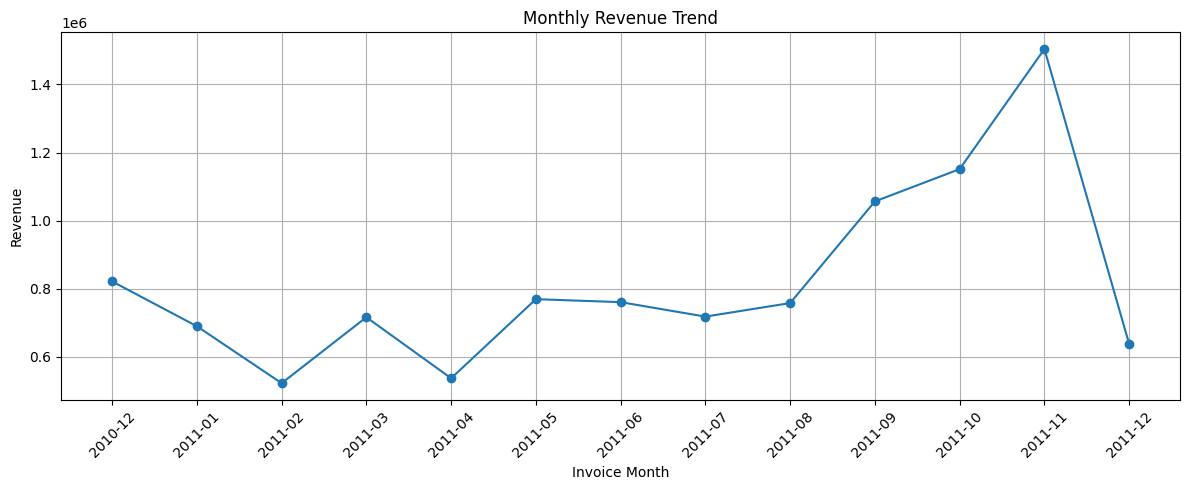

In [192]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue['InvoiceMonth'].astype(str),
    monthly_revenue['Revenue'],
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Invoice Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### Step 6: Analyzing Monthly Order Trends

Calculate the number of unique orders for each month using InvoiceNo. This analysis helps identify changes in order activity and compare monthly order patterns with monthly revenue trends.

In [193]:
monthly_orders = (
    df_sales.groupby('InvoiceMonth')['InvoiceNo']
    .nunique()
    .reset_index(name='Total_Orders')
)

# Calculate percentage of all orders contributed by each month
total_orders = df_sales['InvoiceNo'].nunique()

monthly_orders['Orders_Percentage'] = (
    monthly_orders['Total_Orders'] / total_orders * 100
)

display(monthly_orders.round(2))

,InvoiceMonth,Total_Orders,Orders_Percentage
0,2010-12,1559,7.81
1,2011-01,1086,5.44
2,2011-02,1100,5.51
3,2011-03,1454,7.28
4,2011-04,1246,6.24
5,2011-05,1681,8.42
6,2011-06,1533,7.68
7,2011-07,1475,7.39
8,2011-08,1361,6.82
9,2011-09,1837,9.20


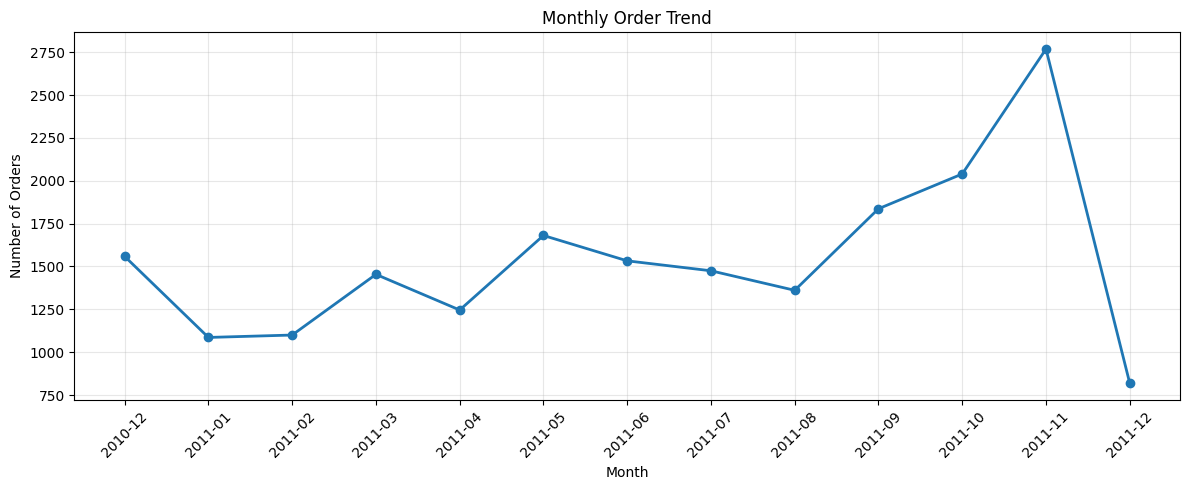

In [194]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_orders['InvoiceMonth'].astype(str),
    monthly_orders['Total_Orders'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Order Trend')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Visualization:** This line chart shows how the number of orders changes from month to month, helping identify trends and changes in purchasing activity.

### Identifying the Top 10 Products by Revenue

Exclude non-merchandise codes representing postage and manual charges from product rankings. Group the remaining merchandise transactions by StockCode, calculate total revenue, total quantity, and number of unique orders, and identify the ten highest revenue-generating products.

In [195]:
# Exclude non-merchandise codes from product rankings
merchandise_sales = df_sales[
    ~df_sales['StockCode'].astype(str).isin(['DOT', 'POST', 'M'])
].copy()

# Calculate total merchandise revenue and quantity
total_merchandise_revenue = merchandise_sales['Revenue'].sum()
total_merchandise_quantity = merchandise_sales['Quantity'].sum()

# Calculate the top 10 merchandise products by revenue
top_products_revenue = (
    merchandise_sales.groupby('StockCode')
    .agg(
        Product_Description=('Description', 'first'),
        Total_Revenue=('Revenue', 'sum'),
        Total_Quantity=('Quantity', 'sum'),
        Number_of_Orders=('InvoiceNo', 'nunique')
    )
    .sort_values(by='Total_Revenue', ascending=False)
    .head(10)
    .reset_index()
)

# Calculate percentage contribution to merchandise revenue and quantity
top_products_revenue['Revenue_Percentage'] = (
    top_products_revenue['Total_Revenue']
    / total_merchandise_revenue * 100
)

top_products_revenue['Quantity_Percentage'] = (
    top_products_revenue['Total_Quantity']
    / total_merchandise_quantity * 100
)

display(top_products_revenue.round(2))

,StockCode,Product_Description,Total_Revenue,Total_Quantity,Number_of_Orders,Revenue_Percentage,Quantity_Percentage
0,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988,1.69,0.25
1,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1,1.64,1.46
2,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104462.75,37641,2198,1.02,0.68
3,47566,PARTY BUNTING,99445.23,18283,1685,0.97,0.33
4,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089,0.92,0.87
5,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247,0.79,1.40
6,23084,RABBIT NIGHT LIGHT,66870.03,30739,994,0.65,0.55
7,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160,0.63,0.35
8,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455,0.57,0.65
9,79321,CHILLI LIGHTS,54096.36,10302,661,0.53,0.19


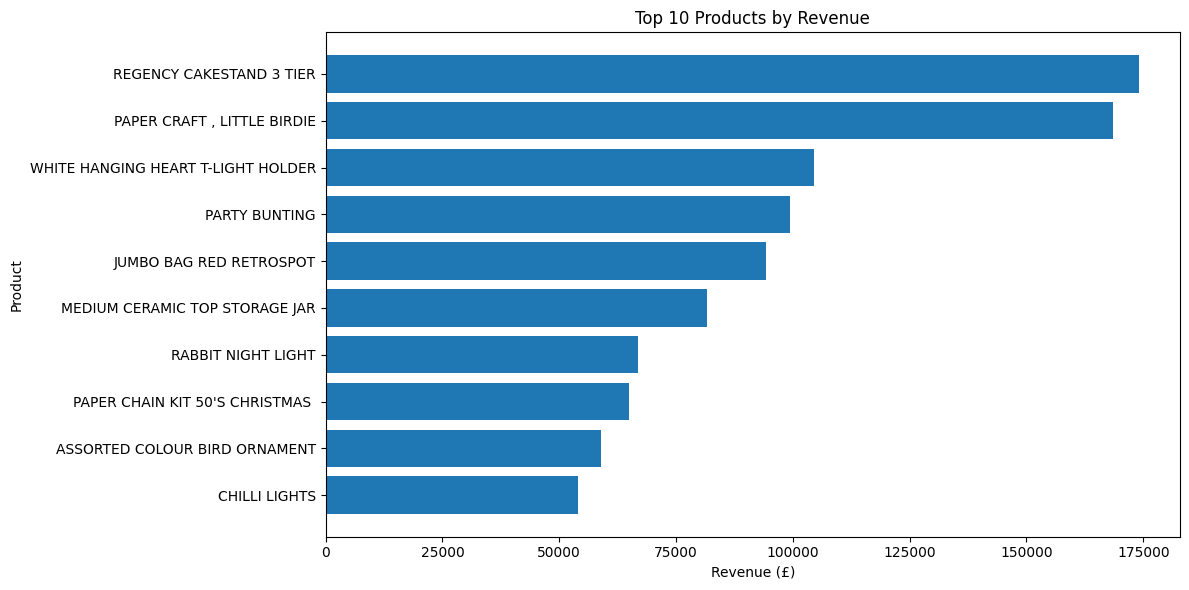

In [196]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products_revenue['Product_Description'],
    top_products_revenue['Total_Revenue']
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue (£)')
plt.ylabel('Product')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Visualization:** This horizontal bar chart compares the top 10 merchandise products by revenue, helping identify the products that contribute the most to sales revenue.

### Identifying the Top 10 Products by Quantity

Calculate the total quantity sold for each merchandise product. Rank products in descending order of total quantity to identify the ten most purchased products.

In [197]:
top_products_quantity = (
    merchandise_sales.groupby('StockCode')
    .agg(
        Product_Description=('Description', 'first'),
        Total_Quantity=('Quantity', 'sum'),
        Total_Revenue=('Revenue', 'sum'),
        Number_of_Orders=('InvoiceNo', 'nunique')
    )
    .sort_values(by='Total_Quantity', ascending=False)
    .head(10)
    .reset_index()
)

# Calculate percentage contribution to total merchandise quantity
top_products_quantity['Quantity_Percentage'] = (
    top_products_quantity['Total_Quantity']
    / total_merchandise_quantity * 100
)

# Calculate percentage contribution to total merchandise revenue
top_products_quantity['Revenue_Percentage'] = (
    top_products_quantity['Total_Revenue']
    / total_merchandise_revenue * 100
)

display(top_products_quantity.round(2))

,StockCode,Product_Description,Total_Quantity,Total_Revenue,Number_of_Orders,Quantity_Percentage,Revenue_Percentage
0,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,1.46,1.64
1,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247,1.40,0.79
2,22197,SMALL POPCORN HOLDER,56898,51334.47,1392,1.02,0.50
3,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535,0.99,0.13
4,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089,0.87,0.92
5,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198,0.68,1.02
6,21212,PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320,0.65,0.21
7,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455,0.65,0.57
8,23084,RABBIT NIGHT LIGHT,30739,66870.03,994,0.55,0.65
9,22492,MINI PAINT SET VINTAGE,26633,16937.82,380,0.48,0.16


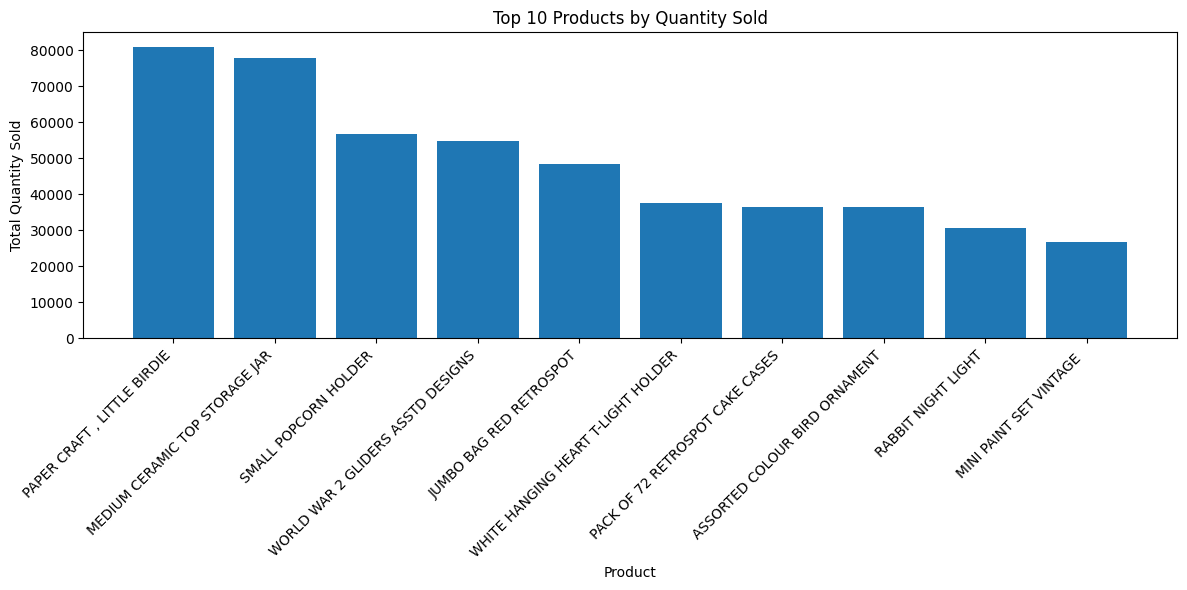

In [198]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_products_quantity['Product_Description'],
    top_products_quantity['Total_Quantity']
)

plt.title('Top 10 Products by Quantity Sold')
plt.xlabel('Product')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Visualization:** This chart compares the total quantities sold for the top 10 products, helping identify the products with the highest sales volume and understand customer purchasing demand.

### Top 10 Customers by Spending

Identify the ten customers who generated the highest total revenue. Calculate their total spending, number of unique orders, and total quantity purchased to understand their contribution to sales.

In [199]:
# Calculate spending for customers with identified CustomerIDs
identified_customer_sales = df_sales[
    df_sales['CustomerID'].notna()
].copy()

total_identified_customer_revenue = (
    identified_customer_sales['Revenue'].sum()
)

top_customers = (
    identified_customer_sales.groupby('CustomerID')
    .agg(
        Total_Spending=('Revenue', 'sum'),
        Number_of_Orders=('InvoiceNo', 'nunique'),
        Total_Quantity=('Quantity', 'sum')
    )
    .sort_values(by='Total_Spending', ascending=False)
    .head(10)
    .reset_index()
)

# Customer contribution among customers with identified IDs
top_customers['Customer_Revenue_Percentage'] = (
    top_customers['Total_Spending']
    / total_identified_customer_revenue * 100
)

# Customer contribution to all valid sales revenue
top_customers['Total_Sales_Revenue_Percentage'] = (
    top_customers['Total_Spending']
    / total_revenue * 100
)

display(top_customers.round(2))

,CustomerID,Total_Spending,Number_of_Orders,Total_Quantity,Customer_Revenue_Percentage,Total_Sales_Revenue_Percentage
0,14646.0,280206.02,73,196915,3.15,2.63
1,18102.0,259657.30,60,64124,2.92,2.44
2,17450.0,194390.79,46,69973,2.19,1.83
3,16446.0,168472.50,2,80997,1.90,1.58
4,14911.0,143711.17,201,80240,1.62,1.35
5,12415.0,124914.53,21,77374,1.41,1.17
6,14156.0,117210.08,55,57768,1.32,1.10
7,17511.0,91062.38,31,64549,1.02,0.86
8,16029.0,80850.84,63,40108,0.91,0.76
9,12346.0,77183.60,1,74215,0.87,0.73


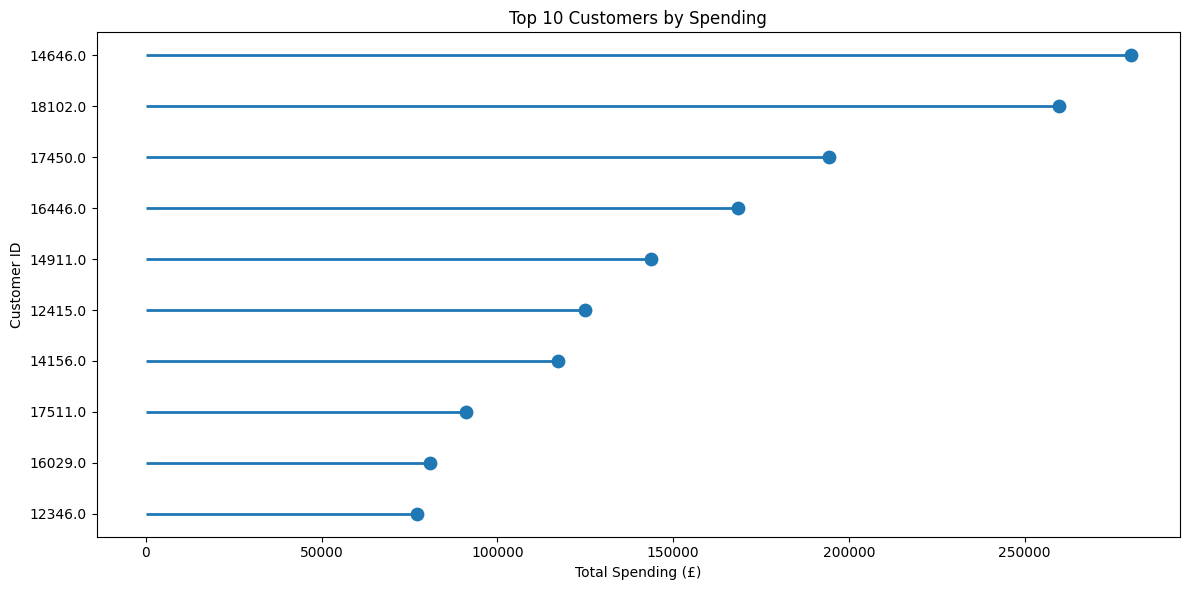

In [200]:
# Sort customers for a clear lollipop chart
customer_chart = top_customers.sort_values(
    by='Total_Spending',
    ascending=True
)

plt.figure(figsize=(12, 6))

plt.hlines(
    y=customer_chart['CustomerID'].astype(str),
    xmin=0,
    xmax=customer_chart['Total_Spending'],
    linewidth=2
)

plt.scatter(
    customer_chart['Total_Spending'],
    customer_chart['CustomerID'].astype(str),
    s=80
)

plt.title('Top 10 Customers by Spending')
plt.xlabel('Total Spending (£)')
plt.ylabel('Customer ID')
plt.tight_layout()
plt.show()

**Visualization:** This lollipop chart highlights the spending of the top 10 identified customers, helping compare customer revenue contributions and identify high-value customers.

### Step 10: Sales Performance by Country

Calculate total revenue and the number of unique orders for each country. Rank countries by revenue to identify the retailer's strongest geographical markets and understand how sales are distributed across different countries.

In [201]:
sales_by_country = (
    df_sales.groupby('Country')
    .agg(
        Total_Revenue=('Revenue', 'sum'),
        Total_Orders=('InvoiceNo', 'nunique')
    )
    .sort_values(by='Total_Revenue', ascending=False)
    .reset_index()
)

# Calculate each country's contribution to overall revenue
sales_by_country['Revenue_Percentage'] = (
    sales_by_country['Total_Revenue'] / total_revenue * 100
)

# Calculate each country's contribution to overall orders
sales_by_country['Orders_Percentage'] = (
    sales_by_country['Total_Orders'] / total_orders * 100
)

display(sales_by_country.round(2))

,Country,Total_Revenue,Total_Orders,Revenue_Percentage,Orders_Percentage
0,United Kingdom,9001744.09,18019,84.59,90.28
1,Netherlands,285446.34,94,2.68,0.47
2,EIRE,283140.52,288,2.66,1.44
3,Germany,228678.40,457,2.15,2.29
4,France,209625.37,392,1.97,1.96
5,Australia,138453.81,57,1.30,0.29
6,Spain,61558.56,90,0.58,0.45
7,Switzerland,57067.60,54,0.54,0.27
8,Belgium,41196.34,98,0.39,0.49
9,Sweden,38367.83,36,0.36,0.18


### Top 10 Countries by Revenue

Visualize the ten countries generating the highest revenue. This chart helps compare the main geographical markets and identify where sales are concentrated.

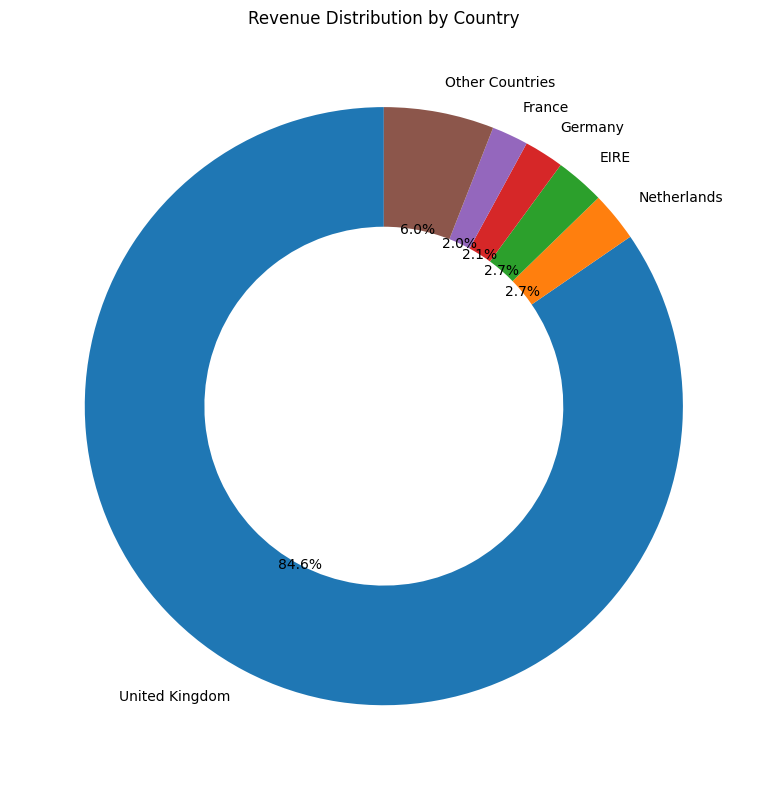

In [202]:
# Prepare country revenue distribution
top_5_countries = sales_by_country.head(5).copy()

other_countries_revenue = (
    sales_by_country.iloc[5:]['Total_Revenue'].sum()
)

country_labels = top_5_countries['Country'].tolist() + ['Other Countries']

country_values = (
    top_5_countries['Total_Revenue'].tolist()
    + [other_countries_revenue]
)

# Create donut chart
plt.figure(figsize=(9, 8))

plt.pie(
    country_values,
    labels=country_labels,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Revenue Distribution by Country')
plt.tight_layout()
plt.show()

**Visualization:** This donut chart shows the revenue contribution of the top five countries compared with the remaining countries combined, helping understand geographical revenue distribution and market concentration.

# Section 4: Customer and Product Analysis

This section examines customer purchasing behaviour, customer revenue contribution, product purchasing patterns, and geographical sales performance. It identifies repeat customers, evaluates the contribution of high-value customers, investigates unusual product transactions, and examines monthly sales patterns and differences between UK and international markets.

### Repeat Customer Analysis

Analyze customer purchasing behavior by counting the unique orders placed by each identified customer. Identify customers who made more than one purchase and calculate the percentage of repeat customers.

In [203]:
# Count unique orders for each identified customer
customer_orders = (
    df_sales[df_sales['CustomerID'].notna()]
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
)

# Calculate total identified customers
total_customers = customer_orders.count()

# Identify customers with more than one order
repeat_customers = (customer_orders > 1).sum()

# Calculate the percentage of repeat customers
repeat_customer_percentage = (
    repeat_customers / total_customers
) * 100

print("Total Identified Customers:", f"{total_customers:,}")
print("Repeat Customers:", f"{repeat_customers:,}")
print("Repeat Customer Percentage:", f"{repeat_customer_percentage:.2f}%")

Total Identified Customers: 4,338
Repeat Customers: 2,845
Repeat Customer Percentage: 65.58%


**Finding:** Out of 4,338 identified customers, 2,845 (65.58%) placed more than one order, while 1,493 customers placed only one order. This indicates that repeat purchasing is common among identified customers.

**Limitation:** Records without CustomerID cannot be linked to individual customers, so they are excluded from this calculation. Repeat purchasing does not necessarily prove customer loyalty or satisfaction.

### Top 10 Customers' Contribution to Total Revenue

Calculate the percentage of total sales revenue generated by the ten highest-spending identified customers. This helps measure their contribution to the retailer's overall revenue.

In [204]:
top_10_customer_revenue = top_customers['Total_Spending'].sum()

top_10_customer_percentage = (
    top_10_customer_revenue / total_revenue
) * 100

print("Top 10 Customers' Revenue:", f"{top_10_customer_revenue:,.2f}")
print("Total Sales Revenue:", f"{total_revenue:,.2f}")
print("Contribution to Total Revenue:", f"{top_10_customer_percentage:.2f}%")

Top 10 Customers' Revenue: 1,537,659.21
Total Sales Revenue: 10,642,110.80
Contribution to Total Revenue: 14.45%


**Finding:** The ten highest-spending identified customers generated 1,537,659.21, representing 14.45% of total sales revenue. This demonstrates that high-value customers contribute meaningfully to the retailer's overall sales.

**Limitation:** This calculation compares the top ten identified customers with total sales revenue, which also includes transactions without CustomerID. Therefore, the percentage represents their contribution to all recorded sales, not just sales linked to identified customers.

### Investigating Unusual Product Purchasing Patterns

Examine the sales transactions for products with unusually high quantities. This helps identify exceptional bulk purchases that may influence product rankings.

In [205]:
unusual_product_sales = df_sales[
    df_sales['StockCode'].astype(str) == '23843'
][[
    'InvoiceNo',
    'InvoiceDate',
    'StockCode',
    'Description',
    'Quantity',
    'UnitPrice',
    'Revenue',
    'CustomerID',
    'Country'
]]

display(unusual_product_sales)

,InvoiceNo,InvoiceDate,StockCode,Description,Quantity,UnitPrice,Revenue,CustomerID,Country
540421,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom


**Finding:** Product 23843 (PAPER CRAFT, LITTLE BIRDIE) recorded 80,995 units and generated 168,469.60 in revenue from one invoice (581483). The transaction was associated with customer 16446 in the United Kingdom on 9 December 2011.

This exceptional bulk purchase significantly influences the product's position in the top 10 rankings by revenue and quantity.

**Limitation:** The dataset identifies the transaction but does not explain why such a large quantity was purchased. It should be treated as an unusual bulk purchase, not automatically as an error.

### Comparing UK and International Sales

Compare revenue generated in the United Kingdom with revenue from all other countries. This helps identify the retailer's dependence on its main geographical market.

In [206]:
uk_revenue = sales_by_country.loc[
    sales_by_country['Country'] == 'United Kingdom',
    'Total_Revenue'
].sum()

international_revenue = (
    total_revenue - uk_revenue
)

uk_percentage = (uk_revenue / total_revenue) * 100

international_percentage = (
    international_revenue / total_revenue
) * 100

print("UK Revenue:", f"{uk_revenue:,.2f}")
print("International Revenue:", f"{international_revenue:,.2f}")
print("UK Revenue Percentage:", f"{uk_percentage:.2f}%")
print("International Revenue Percentage:", f"{international_percentage:.2f}%")

UK Revenue: 9,001,744.09
International Revenue: 1,640,366.71
UK Revenue Percentage: 84.59%
International Revenue Percentage: 15.41%


**Finding:** The United Kingdom generated 9,001,744.09, representing 84.59% of total revenue. International markets generated 1,640,366.71, representing 15.41%.

This shows that the retailer depends heavily on its UK market, while international countries provide a smaller share of overall revenue.

**Limitation:** International revenue is combined across all other countries. Individual country performance varies, and this comparison does not explain the reasons behind those differences.

### Identifying Monthly Sales Patterns

Examine monthly revenue to identify the highest and lowest revenue months and understand changes in sales performance throughout the recorded period.

In [207]:
highest_revenue_month = monthly_revenue.loc[
    monthly_revenue['Revenue'].idxmax()
]

lowest_revenue_month = monthly_revenue.loc[
    monthly_revenue['Revenue'].idxmin()
]

print(
    "Highest Revenue Month:",
    highest_revenue_month['InvoiceMonth'],
    f"({highest_revenue_month['Revenue']:,.2f})"
)

print(
    "Lowest Revenue Month:",
    lowest_revenue_month['InvoiceMonth'],
    f"({lowest_revenue_month['Revenue']:,.2f})"
)

Highest Revenue Month: 2011-11 (1,503,866.78)
Lowest Revenue Month: 2011-02 (522,545.56)


**Finding:** November 2011 recorded the highest monthly revenue of 1,503,866.78, while February 2011 recorded the lowest at 522,545.56. Revenue increased considerably from September through November 2011 before declining in December.

**Limitation:** The dataset covers December 2010 to December 2011, so it does not provide multiple years of data for reliable year-over-year comparisons or confirmation of recurring seasonal patterns.

### Customer and Product Analysis — Key Findings

1. **Customer revenue contribution:** The top 10 identified customers generated 1,537,659.21, representing 14.45% of total sales revenue.

2. **Repeat purchasing:** Out of 4,338 identified customers, 2,845 (65.58%) placed more than one order.

3. **Product revenue:** REGENCY CAKESTAND 3 TIER was the highest-revenue merchandise product, generating 174,156.54.

4. **Product quantity:** PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity at 80,995 units. This result was driven by one unusually large transaction.

5. **Country performance:** The United Kingdom generated 84.59% of total revenue, while international markets contributed 15.41%.

6. **Monthly sales trends:** November 2011 recorded the highest monthly revenue (1,503,866.78), while February 2011 recorded the lowest (522,545.56).

### Analysis Limitations

- Records without CustomerID cannot be linked to individual customers and are excluded from customer-level analysis.
- The dataset covers only December 2010 to December 2011, limiting long-term trend and seasonal analysis.
- An unusually large transaction for product 23843 influenced its product rankings. The available data does not establish whether the transaction was erroneous.
- Revenue and order counts describe recorded transactions but do not explain the reasons behind customer purchasing decisions.
- Country-level revenue comparisons do not account for differences in market size, operating costs, or profitability.
- The analysis uses sales revenue rather than profit because product costs and operating expenses are not available.

## Pareto Principle – Customer Revenue Concentration

The Pareto Principle, commonly known as the 80/20 rule, suggests that approximately 80% of outcomes may come from 20% of contributors. It is a guideline, not a rule that every dataset must follow.

For this analysis, all identified customers are ranked from highest to lowest revenue.

The calculation follows these steps:

1. Calculate each customer's total revenue.
2. Sort customers from highest to lowest revenue.
3. Calculate each customer's percentage contribution to total revenue from identified customers.
4. Calculate the cumulative revenue contribution percentage.
5. Measure the revenue contribution of the top 20% of customers.
6. Identify how many customers are required to reach at least 80% of customer revenue.

The results will show whether customer revenue concentration in this dataset follows, approximately follows, or differs from the traditional 80/20 principle.

Total identified customers: 4,338
Top 20% of customers: 868
Revenue from top 20%: 74.68%
Customers needed to reach 80% revenue: 1,130
Percentage of customers needed to reach 80%: 26.05%


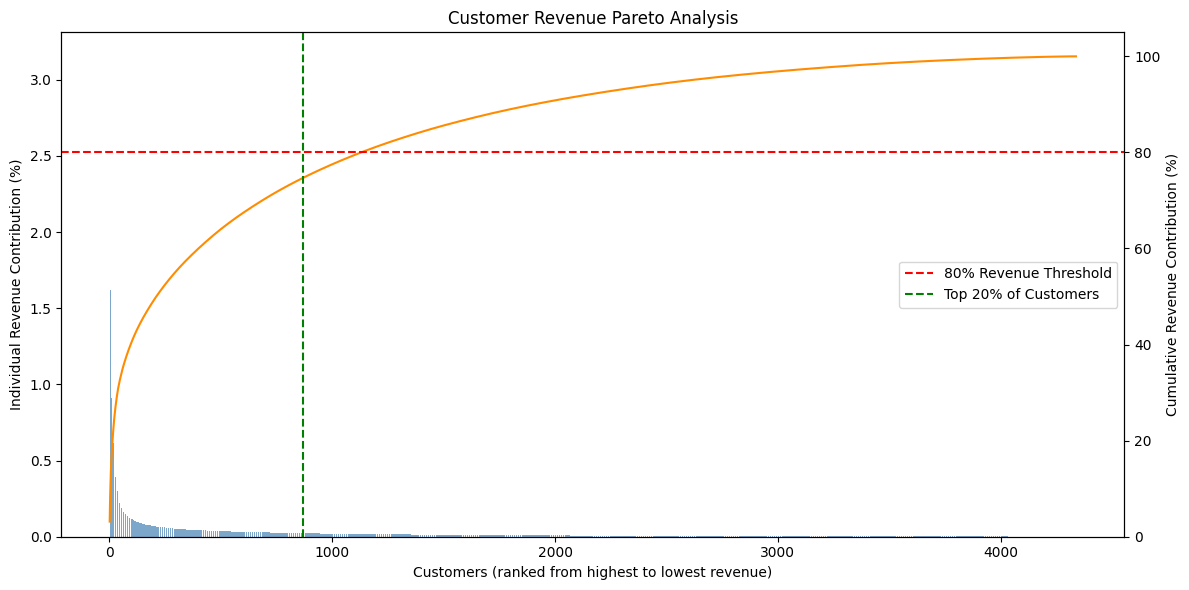

In [208]:

# Calculate revenue for every identified customer
customer_pareto = (
    identified_customer_sales.groupby('CustomerID')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index(name='Customer_Revenue')
)

# Calculate each customer's revenue contribution
customer_pareto['Revenue_Percentage'] = (
    customer_pareto['Customer_Revenue']
    / customer_pareto['Customer_Revenue'].sum() * 100
)

# Calculate cumulative revenue contribution
customer_pareto['Cumulative_Percentage'] = (
    customer_pareto['Revenue_Percentage'].cumsum()
)

# Measure the top 20% of customers
top_20_count = int(np.ceil(len(customer_pareto) * 0.20))
top_20_revenue_percentage = (
    customer_pareto.head(top_20_count)['Revenue_Percentage'].sum()
)

# Calculate customers needed to reach 80% of revenue
customers_to_80 = (
    customer_pareto['Cumulative_Percentage'] >= 80
).idxmax() + 1

customers_to_80_percentage = (
    customers_to_80 / len(customer_pareto) * 100
)

print(f"Total identified customers: {len(customer_pareto):,}")
print(f"Top 20% of customers: {top_20_count:,}")
print(f"Revenue from top 20%: {top_20_revenue_percentage:.2f}%")
print(f"Customers needed to reach 80% revenue: {customers_to_80:,}")
print(f"Percentage of customers needed to reach 80%: "
      f"{customers_to_80_percentage:.2f}%")

# Pareto chart
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    range(1, len(customer_pareto) + 1),
    customer_pareto['Revenue_Percentage'],
    color='steelblue',
    alpha=0.7
)
ax1.set_xlabel('Customers (ranked from highest to lowest revenue)')
ax1.set_ylabel('Individual Revenue Contribution (%)')
ax1.set_title('Customer Revenue Pareto Analysis')

ax2 = ax1.twinx()
ax2.plot(
    range(1, len(customer_pareto) + 1),
    customer_pareto['Cumulative_Percentage'],
    color='darkorange'
)
ax2.axhline(80, linestyle='--', color='red', label='80% Revenue Threshold')
ax2.axvline(top_20_count, linestyle='--', color='green',
            label='Top 20% of Customers')
ax2.set_ylabel('Cumulative Revenue Contribution (%)')
ax2.set_ylim(0, 105)
ax2.legend(loc='center right')

plt.tight_layout()
plt.show()


### Customer Pareto Analysis – Interpretation

The Customer Pareto Analysis examined 4,338 identified customers to understand the distribution of revenue across the customer base.

The top 20% of customers (868 customers) contributed 74.68% of identified customer revenue. To reach 80% of identified customer revenue, 1,130 customers, representing 26.05% of the customer base, were required.

This indicates that customer revenue is concentrated among a relatively small group of high-value customers. However, the distribution does not follow the exact traditional 80/20 rule, because the top 20% of customers contributed less than 80% of revenue.

**Business implication:** The company should prioritize retaining its high-value customers while encouraging other customers to increase their purchasing frequency and spending.

## Pareto Principle – Product Revenue Concentration

This analysis evaluates whether product revenue follows the approximate 80/20 principle.

Only merchandise products are included. Non-merchandise codes such as DOT, POST, and M are excluded to keep the analysis focused on products sold.

The calculation follows these steps:

1. Calculate total revenue for every merchandise product.
2. Rank products from highest to lowest revenue.
3. Calculate each product's percentage contribution to total merchandise revenue.
4. Calculate the cumulative revenue contribution.
5. Calculate the contribution of the top 20% of products.
6. Identify the number and percentage of products needed to generate at least 80% of merchandise revenue.

The results help management understand revenue concentration and identify products that contribute most to sales.

Total merchandise products: 3,919
Top 20% of products: 784
Revenue from top 20%: 78.84%
Products needed to reach 80% revenue: 825
Percentage of products needed to reach 80%: 21.05%


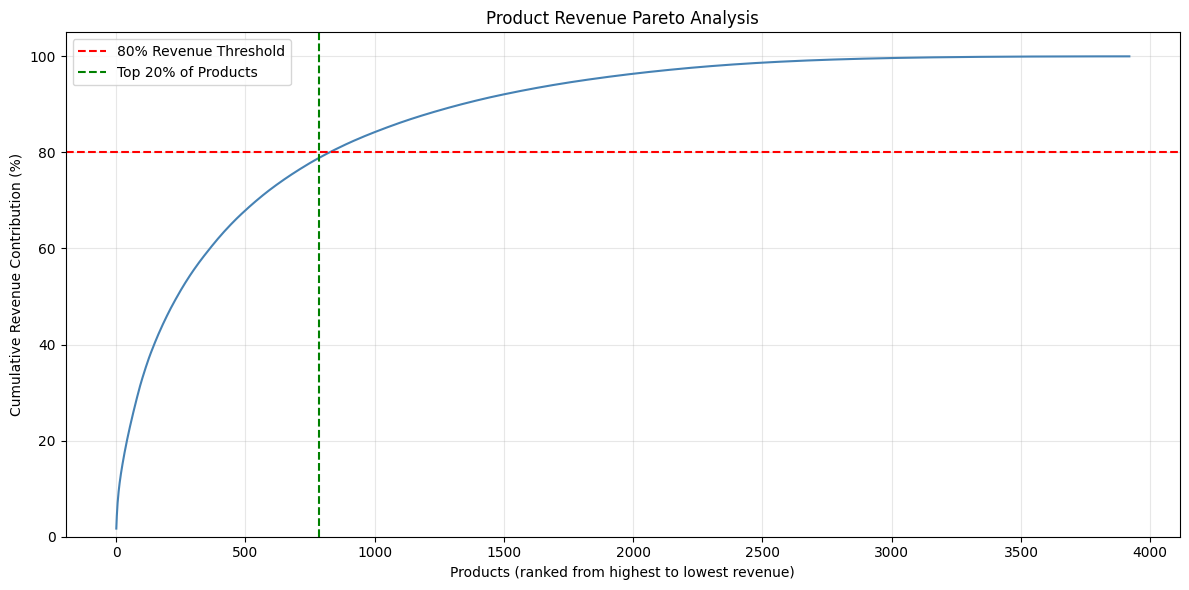

In [209]:

# Calculate revenue for all merchandise products
product_pareto = (
    merchandise_sales.groupby('StockCode')
    .agg(
        Product_Description=('Description', 'first'),
        Product_Revenue=('Revenue', 'sum')
    )
    .sort_values(by='Product_Revenue', ascending=False)
    .reset_index()
)

# Calculate percentage contribution of each product
product_pareto['Revenue_Percentage'] = (
    product_pareto['Product_Revenue']
    / product_pareto['Product_Revenue'].sum() * 100
)

# Calculate cumulative revenue contribution
product_pareto['Cumulative_Percentage'] = (
    product_pareto['Revenue_Percentage'].cumsum()
)

# Measure revenue contribution of the top 20% of products
top_20_products_count = int(np.ceil(len(product_pareto) * 0.20))

top_20_products_revenue_percentage = (
    product_pareto.head(top_20_products_count)['Revenue_Percentage'].sum()
)

# Calculate number of products needed to reach 80% revenue
products_to_80 = (
    product_pareto['Cumulative_Percentage'] >= 80
).idxmax() + 1

products_to_80_percentage = (
    products_to_80 / len(product_pareto) * 100
)

print(f"Total merchandise products: {len(product_pareto):,}")
print(f"Top 20% of products: {top_20_products_count:,}")
print(f"Revenue from top 20%: "
      f"{top_20_products_revenue_percentage:.2f}%")
print(f"Products needed to reach 80% revenue: {products_to_80:,}")
print(f"Percentage of products needed to reach 80%: "
      f"{products_to_80_percentage:.2f}%")

# Pareto cumulative contribution chart
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(product_pareto) + 1),
    product_pareto['Cumulative_Percentage'],
    color='steelblue'
)

plt.axhline(80, linestyle='--', color='red',
            label='80% Revenue Threshold')

plt.axvline(top_20_products_count, linestyle='--', color='green',
            label='Top 20% of Products')

plt.xlabel('Products (ranked from highest to lowest revenue)')
plt.ylabel('Cumulative Revenue Contribution (%)')
plt.title('Product Revenue Pareto Analysis')
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Product Pareto Analysis – Interpretation

The Product Pareto Analysis examined 3,919 merchandise products to understand how revenue is distributed across products.

The top 20% of products (784 products) contributed 78.84% of total merchandise revenue. Furthermore, 825 products, representing 21.05% of all merchandise products, were required to generate 80% of merchandise revenue.

These results show that product revenue distribution closely follows the traditional Pareto Principle. A relatively small proportion of products generates the majority of merchandise revenue.

**Business implication:** The company should prioritize stock availability, inventory management, and promotional activities for high-revenue products. Lower-revenue products can be reviewed to identify whether they should be improved, promoted, or reconsidered.

### Exporting the Cleaned Dataset

Export the cleaned sales dataset to a CSV file for future use in the Power BI dashboard and other analysis. Remove the temporary InvoiceMonth column because it is an analysis helper column and is not required in the final cleaned dataset.

In [210]:
cleaned_dataset = df_sales.drop(
    columns=['InvoiceMonth'],
    errors='ignore'
)

cleaned_dataset.to_csv(
    "/content/drive/MyDrive/Online_Retail_Cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Dataset shape:", cleaned_dataset.shape)

Cleaned dataset exported successfully!
Dataset shape: (524878, 9)


### **Section 5: Business Insights and Recommendations**

### Business Insight 1: Products Generating the Highest Revenue

The REGENCY CAKESTAND 3 TIER generated the highest merchandise revenue, with total revenue of £174,156.54. PAPER CRAFT, LITTLE BIRDIE ranked second, generating £168,469.60. However, its revenue came from one unusually large transaction, so this result should be interpreted carefully.

These findings show which products contributed most to merchandise sales revenue during the analysis period.

### Business Insight 2: Products with the Highest Sales Quantity

PAPER CRAFT, LITTLE BIRDIE recorded the highest quantity sold, with 80,995 units, followed by MEDIUM CERAMIC TOP STORAGE JAR with 78,033 units and SMALL POPCORN HOLDER with 56,898 units.

However, PAPER CRAFT, LITTLE BIRDIE's total quantity came from one unusually large order. Therefore, its high sales quantity may reflect a bulk purchase rather than regular customer demand.

These findings help identify products with high sales volumes and support inventory planning. The results should be considered alongside the number of orders for each product.

### Business Insight 3: Countries Contributing the Most Revenue

The United Kingdom generated the highest revenue, with £9,001,744.09, representing approximately 84.59% of total sales revenue. The Netherlands ranked second with £285,446.34, followed by EIRE with £283,140.52, Germany with £228,678.40, and France with £209,625.37.

All countries outside the United Kingdom contributed approximately 15.41% of total revenue.

These findings show that the business depends heavily on its UK market, while international markets provide additional revenue opportunities.

### Business Insight 4: Months with the Highest and Lowest Sales

November 2011 recorded the highest monthly revenue, with £1,503,866.78, while February 2011 recorded the lowest, with £522,545.56.

Monthly revenue increased significantly from September to November 2011 before declining in December.

These findings highlight changes in monthly sales performance and can help the business plan inventory and sales activities. However, the dataset covers only December 2010 to December 2011, so it is not sufficient to establish long-term seasonal patterns.

### Business Insight 5: Customers Contributing the Most Revenue

Customer 14646 was the highest revenue-contributing customer, generating £280,206.02, followed by Customer 18102 with £259,657.30 and Customer 17450 with £194,390.79.

The top 10 identified customers generated a combined revenue of £1,537,659.21, representing approximately 14.45% of total sales revenue.

These findings show that a small group of customers contributes a meaningful share of the business's revenue. The analysis includes only transactions with identifiable CustomerID values because customers with missing IDs cannot be reliably identified.

### Business Insight 6: Customer Purchasing Patterns

The analysis identified several purchasing patterns:

1. **Repeat purchasing:** Out of 4,338 identified customers, 2,845 were repeat customers, representing 65.58%. This indicates that many identifiable customers made multiple purchases during the analysis period.

2. **Bulk purchasing:** PAPER CRAFT, LITTLE BIRDIE recorded 80,995 units sold from one order. This represents an unusually large purchase and should not automatically be interpreted as regular customer demand.

3. **Monthly sales patterns:** Revenue increased from September to November 2011, with November recording the highest monthly revenue, followed by a decline in December.

4. **Customer revenue concentration:** The top 10 customers contributed 14.45% of total revenue, showing that a relatively small group of customers generated a meaningful share of sales.

These patterns can help the business understand customer activity, identify unusual purchasing behaviour, and support sales and inventory planning. Customer-level findings exclude transactions with missing CustomerID values.

## Business Recommendations

Based on the analysis, the following three recommendations are proposed:

### 1. Improve Product and Inventory Planning

The business should monitor high-revenue products, such as REGENCY CAKESTAND 3 TIER, and maintain sufficient stock. Inventory planning should consider both revenue and order frequency. For example, PAPER CRAFT, LITTLE BIRDIE recorded 80,995 units from one unusually large order, so its demand should be investigated before making regular stock forecasts.

### 2. Expand International Markets

The United Kingdom contributed approximately 84.59% of total revenue. The business should explore opportunities to increase sales in international markets, particularly the Netherlands, EIRE, Germany, and France. This could help reduce dependence on the UK market and diversify revenue.

### 3. Strengthen Customer Retention

Approximately 65.58% of identified customers made repeat purchases. The business should introduce loyalty initiatives, personalized offers, and targeted promotions to encourage repeat purchases. It should also maintain strong relationships with high-value customers, as the top 10 customers contributed approximately 14.45% of total revenue.